In [128]:
# importing packages and styling plots
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
import numpy as np
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})

dpi=100

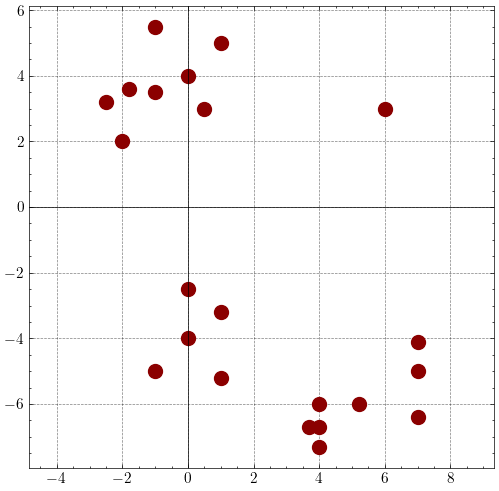

In [129]:
# read (big) dataset and name dimensions
bigd = pd.read_csv('data/big-dataset.csv', header=None)
bigd.columns = ['x', 'y']

# visualize
plt.figure(figsize=(6, 6))

plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)
plt.scatter(bigd.x, bigd.y, s=100, color="darkred")
plt.axis('equal')

plt.savefig('output/dataviz.png', dpi=dpi)
plt.show()

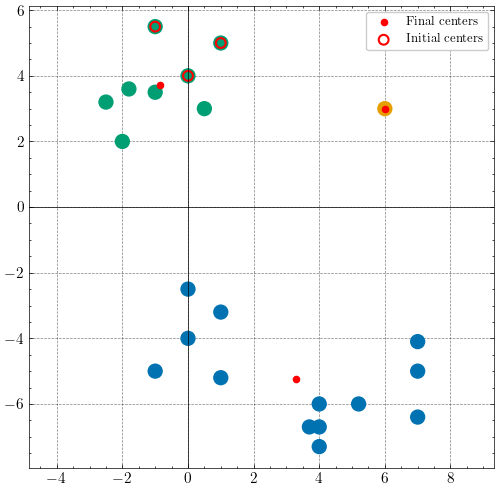

In [130]:
# fitting k means with hand-picked initial centers
colors = ListedColormap(['#0072B2', '#E69F00', '#009E73'])

X = bigd[['x', 'y']].to_numpy()
centers = np.array([[0,4], [1,5], [-1,5.5]])

model = KMeans(n_clusters=3, init=centers, n_init=1)
model.fit(X)

# visualize
plt.figure(figsize=(6, 6))
plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)

plt.scatter(bigd.x, bigd.y, c=model.labels_, cmap=colors, s=100)

plt.scatter(*model.cluster_centers_.T, color='red', s=20, label='Final centers')

plt.scatter(*centers.T, facecolors='none', edgecolors='red',
            marker='o', s=50, linewidths=1.5, label='Initial centers')

plt.axis('equal')
plt.legend()
plt.savefig('output/cluster_handpicked_initialization.png', dpi=dpi)
plt.show()

In [131]:
def repeated_kmeans(
        repetations=40, init='uniform', random_state=69,
        cluster_colors=colors, savefig_name='output/fig.png',
    ):

    # only used for uniformly drawn initializations
    rng = np.random.default_rng(42)

    # used for both
    results = []

    # 40 random initializations
    for _ in range(repetations):
        centers = X[rng.choice(len(X), size=3, replace=False)].copy()

        if init == 'k-means++':
            model = KMeans(n_clusters=3, init='k-means++', n_init=1, random_state=random_state)
        elif init == 'uniform':
            model = KMeans(n_clusters=3, init=centers, n_init=1)
        else: 
            Warning('Choose either k-means++ or uniform as initialization method:).')
            
        model.fit(X)

        results.append((model.inertia_, centers, model))

    # select lowest loss
    best_loss = min(r[0] for r in results)
    n_best = sum(np.isclose(r[0], best_loss) for r in results)
    _, centers, model = min(results, key=lambda r: r[0])

    print(f"Lowest k-means loss: {best_loss:.4f}")
    print(f"Minimum encountered: {n_best}/40 times")

    plt.figure(figsize=(6, 6))
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)

    # data points colored by final cluster
    plt.scatter(bigd.x, bigd.y, c=model.labels_, cmap=cluster_colors, s=100)

    # final centers
    plt.scatter(*model.cluster_centers_.T, color='red', s=30,
                label='Final centers')

    plt.axis('equal')
    plt.legend()
    plt.savefig(savefig_name, dpi=dpi)
    plt.show()

Lowest k-means loss: 93.6729
Minimum encountered: 17/40 times


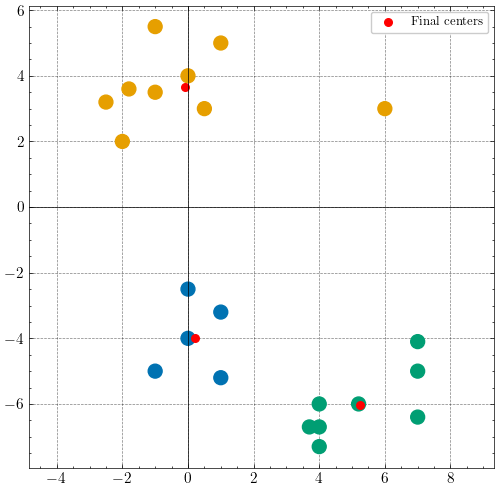

In [132]:
repeated_kmeans(
    repetations=40, init='uniform', cluster_colors=colors,
    savefig_name='output/cluster_uniform_minimizing_kmeansloss.png'
)

Lowest k-means loss: 93.6729
Minimum encountered: 40/40 times


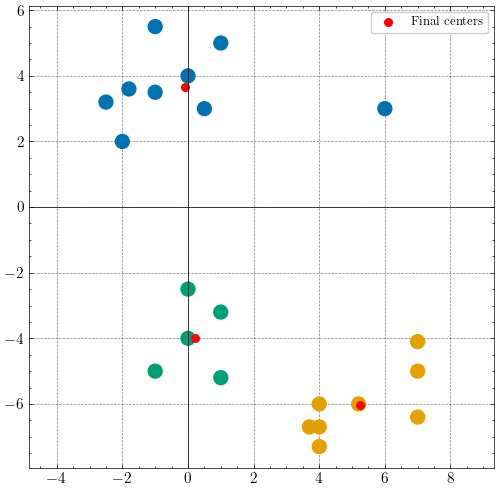

In [133]:
repeated_kmeans(
    repetations=40, init='k-means++', cluster_colors=colors,
    savefig_name='output/cluster_kmeanspp_minimizing_kmeansloss.png'
)

In [134]:
# t-SNE and PCA for visualization of vis-dataset.csv / vis-dataset.txt

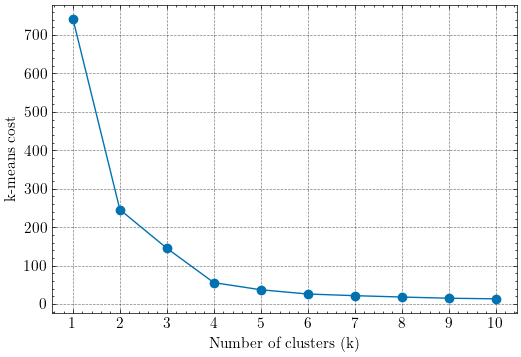

In [ ]:
# k-means cost for different numbers of clusters (for data.csv / data.txt)
data = pd.read_csv('data/data.csv', header=None)
data = data.to_numpy()

ks = range(1, 11)
losses = []

for k in ks:
    model = KMeans(n_clusters=k, init='k-means++',
                   n_init=40, random_state=42)
    model.fit(data)
    losses.append(model.inertia_)

# visualize
plt.figure(figsize=(6, 4))
plt.plot(ks, losses, 'o-', color='#0072B2')
plt.xlabel('Number of clusters (k)')
plt.ylabel('k-means cost')
plt.xticks(ks)

plt.savefig('output/elbow_plot.png', dpi=dpi)
plt.show()